In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpltPath
import pandas as pd
import random
import cloudpickle as cp
#from chainconsumer import Chain, ChainConsumer, Truth, PlotConfig
from chainconsumer import ChainConsumer


import torch
import torch.nn as nn

from sbi import __version__ as sbi_version
from sbi.inference import SNPE_C
from sbi.utils import BoxUniform
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

# Set random seeds for reproducibility
RANDOM_SEED = 42

# Set Python random seed
random.seed(RANDOM_SEED)

# Set NumPy random seed
np.random.seed(RANDOM_SEED)

# Set PyTorch random seed
torch.manual_seed(RANDOM_SEED)

# Set CUDA random seed if available
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    # Make CUDA operations deterministic (may impact performance)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set environment variable for additional reproducibility
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)

print(f"SBI version: {sbi_version}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"CUDA deterministic: {torch.backends.cudnn.deterministic}")
print(f"Random seed set to: {RANDOM_SEED}")


SBI version: 0.21.0
Using device: cuda
GPU name: NVIDIA A100 80GB PCIe
GPU memory: 85.3 GB
CUDA deterministic: True
Random seed set to: 42


# Load Data

In [3]:
training_index = np.load('training_set_1000_index.npy')

# Load measured 2PCFs
x_train = np.load('./data/2PCF_wide_realization0_mean.npy').reshape(1250, -1)[training_index]

# Load cosmological parameters as training data
param_names = ['Om', 'sigma8', 'w0']
param_names_latex = [r"$\Omega_m$", r"$\sigma_8$", r"$w_0$"]
y_train = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T[training_index]

# Convert to tensors and ensure they stay on GPU
y_train = torch.tensor(y_train, dtype=torch.float32, device=device)
x_train = torch.tensor(x_train, dtype=torch.float32, device=device)

# Define prior bounds for the parameters (Om, sigma8, w0) as the min and max of the training data
prior_min = y_train.min(0)[0].flatten()
prior_max = y_train.max(0)[0].flatten()
prior = BoxUniform(low=prior_min, high=prior_max, device=device)

# Define the (irregular) boundaries of the parameter space
boundary_Om_sig8 = np.array([
    [0.1, 1.4],
    [0.2, 1.4],
    [0.5, 0.65],
    [0.5, 0.4],
    [0.3, 0.4],
    [0.1, 0.9],])

boundary_Om_w0 = np.array([
    [.1, -1.1],
    [.5, -2.],
    [.5, -.33],
    [.1, -.33],])

# Functions to check if a point is within the given 2D parameter spaces
validOS = mpltPath.Path(boundary_Om_sig8)
validOW = mpltPath.Path(boundary_Om_w0)

# Function to remove points that are outside the parameter space
def remove_invalid_points(samples):
    in_os = validOS.contains_points(samples[:,(0,1)])
    in_ow = validOW.contains_points(samples[:,(0,2)])
    return samples[in_os & in_ow]


# Set Up Compression Network

In [4]:
# Define a simple linear compression neural net
class LinearCompressor(nn.Module):
    def __init__(self, input_dim=100, output_dim=20):
        super(LinearCompressor, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim, bias=False)
        
    def forward(self, x):
        return self.linear(x)

# Instantiate the model and move to GPU if available
compressor = LinearCompressor(input_dim=100, output_dim=8).to(device=device)

# Verify compressor is on correct device
print(f"Compressor device: {next(compressor.parameters()).device}")

# Function to initialize neural network weights deterministically
def init_weights_deterministic(m):
    """Initialize neural network weights deterministically"""
    if isinstance(m, nn.Linear):
        torch.nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            torch.nn.init.zeros_(m.bias)


# Apply deterministic weight initialization
_ = compressor.apply(init_weights_deterministic)



Compressor device: cuda:0


# Train Normalizing Flow

In [5]:
# Define the MAF density estimator
density_estimator = posterior_nn(
    model='maf',
    embedding_net=compressor,
    num_transforms=4,         # number of MADEs
    num_blocks=3,             # number of layers in each MADE
    hidden_features=128,      # number of hidden units per layer
)

# Set up SNPE_C with the MAF as density estimator and the compressor as embedding network
inference = SNPE_C(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)

_ = inference.append_simulations(y_train, x_train).train(
    training_batch_size=32, 
    learning_rate=1e-4, 
    stop_after_epochs=20,
    max_num_epochs=1024,
    show_train_summary=True
)

posterior = inference.build_posterior()

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/user_input_checks.py:435: UserWarning: Mismatch between the device of the data fed to the embedding_net and the device of the embedding_net's weights. Fed data has device 'cpu' vs embedding_net weights have device 'cuda:0'. Automatically switching the embedding_net's device to 'cpu', which could otherwise be done manually using the line `embedding_net.to('cpu')`.
  warnings.warn(


 Neural network successfully converged after 134 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 134
        Best validation performance: 5.1996
        -------------------------
        
DANGER!!!! No more deepycopy after training!!!


# Sample Posterior

In [6]:
compressed_2pt = inference._neural_net._embedding_net(x_train).detach().cpu().numpy()
np.save("./data/compressed_2pt_1000.npy",compressed_2pt)

In [13]:
testing_data.shape

NameError: name 'testing_data' is not defined

In [14]:
x_test = torch.tensor(np.load("./data/2PCF_fiducial_idx0.npy").flatten(), dtype=torch.float32, device=device)
compressed_2pt_fid = inference._neural_net._embedding_net(x_test).detach().cpu().numpy()
np.save("./data/compressed_2pt_fid_1000.npy",compressed_2pt_fid)

In [16]:
compressed_2pt = np.load('./data/compressed_2pt_1000.npy')
reshaped = np.repeat(compressed_2pt,50,axis=0).reshape((1000,50,8))

Drawing 1000000 posterior samples:   0%|          | 0/1000000 [00:00<?, ?it/s]

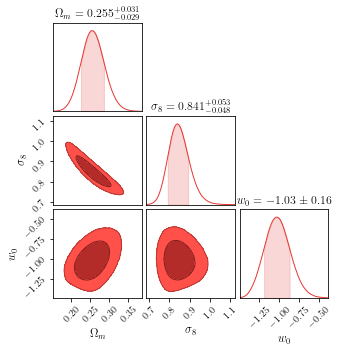

In [8]:
# Load test data
x_test = torch.tensor(np.load("./data/2PCF_fiducial_idx0.npy").flatten(), dtype=torch.float32, device=device)
y_test = np.array([.26, .84, -1.])

# Sample posterior
samples = posterior.sample((1000000,), x=x_test).cpu().numpy()
samples = remove_invalid_points(samples)
np.save("./data/25latent_2PCF_samples_1000.npy", samples)

c = ChainConsumer()

# Create DataFrame for posterior samples
post_df = pd.DataFrame(samples, columns=param_names_latex)

# Create dictionary of truth values
truth_dict = dict(zip(param_names_latex, y_test))

# Add chain & truth to ChainConsumer
c.add_chain(post_df, name="2PCF", color='r')#, sigmas=[0,1,2])
#c.add_truth(Truth(location=truth_dict))


# Set plot configuration
'''
c.set_plot_config(
    PlotConfig(
        contour_label_font_size=36,
        label_font_size=18,
        tick_font_size=16,
        #watermark="Preliminary",
    )
)
'''

fig = c.plotter.plot() 



# Compare to C3NN

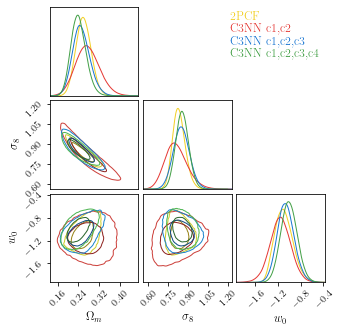

In [14]:
# Load posterior samples
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]
samples_C3NN_2 = np.load("/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std.npy")[::10,(0,1,2)]
samples_C3NN_3 = np.load("/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std.npy")[::10,(0,1,2)]
samples_C3NN_4 = np.load("/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy")[::10,(0,1,2)]

c = ChainConsumer()

# Create DataFrames for each posterior
post_2PCF = pd.DataFrame(samples_2PCF, columns=param_names_latex)
post_C3NN_2 = pd.DataFrame(samples_C3NN_2, columns=param_names_latex)
post_C3NN_3 = pd.DataFrame(samples_C3NN_3, columns=param_names_latex)
post_C3NN_4 = pd.DataFrame(samples_C3NN_4, columns=param_names_latex)

truth_dict = dict(zip(param_names_latex, y_test))

# Add truth and chains to ChainConsumer
#c.add_truth(Truth(location=truth_dict))
#c.add_chain(Chain(samples=post_2PCF, name="2PCF", color='y', sigmas=[0,1,2]))
#c.add_chain(Chain(samples=post_C3NN_2, name="C3NN {c1,c2}", color='r', sigmas=[0,1,2]))
#c.add_chain(Chain(samples=post_C3NN_3, name="C3NN {c1,c2,c3}", color='b', sigmas=[0,1,2]))
#c.add_chain(Chain(samples=post_C3NN_4, name="C3NN {c1,c2,c3,c4}", color='g', sigmas=[0,1,2]))
c.add_chain(post_2PCF, name="2PCF", color='y')
c.add_chain(post_C3NN_2, name="C3NN {c1,c2}", color='r')
c.add_chain(post_C3NN_3, name="C3NN {c1,c2,c3}", color='b')
c.add_chain(post_C3NN_4, name="C3NN {c1,c2,c3,c4}", color='g')

# Set plot configuration
'''
c.set_plot_config(
    PlotConfig(
        contour_label_font_size=36,
        label_font_size=18,
        tick_font_size=16,
        #watermark="Preliminary",
    )
)
'''

fig = c.plotter.plot() 

